
<img src="../../images/brownbear.png" width="400">

## A financial tool that can analyze and maximize investment portfolios on a risk adjusted basis  


Description: This notebook is useful for examining potfolios comprised of generic asset classes and asset subclasses.  Construct portfolios of generic asset classes and examine the results of different weighting schemes.


In [1]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import brownbear as bb

# format price data
pd.options.display.float_format = '{:0.2f}'.format

# display all rows
pd.set_option('display.max_rows', None)

# do not truncate column names
pd.set_option('display.max_colwidth', None)

%matplotlib inline

In [3]:
# set size of inline plots
'''note: rcParams can't be in same cell as import matplotlib
   or %matplotlib inline
   
   %matplotlib notebook: will lead to interactive plots embedded within
   the notebook, you can zoom and resize the figure
   
   %matplotlib inline: only draw static images in the notebook
'''
plt.rcParams["figure.figsize"] = (10, 7)

### Some Globals

In [4]:
investment_universe = ['asset-class-galaxy']

In [5]:
# Fetch Investment Options - all values annualized
df = bb.fetch(investment_universe, risk_free_rate=0, annual_returns='5 Yr', standard_deviation='SD 5 Yr')
df = df.drop('Description', axis=1)
df

,Investment Option,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
0,US Stocks,US Stocks,8.84,26.86,20.24,21.02,21.37,12.16,10.77,4.16,12.46,13.19,16.03,12.16,16.03,0.76
1,Global Stocks,Global Stocks,8.90,10.26,26.14,26.36,20.28,9.84,11.13,6.02,13.34,11.92,15.09,9.84,15.09,0.65
2,US Bonds,US Bonds,-2.29,-3.78,1.97,2.43,4.34,-0.28,4.27,2.17,3.11,5.54,6.41,-0.28,6.41,-1.79
3,Global Bonds,Global Bonds,-3.18,-3.76,1.02,1.26,3.90,-0.13,3.81,2.01,3.30,4.19,5.29,-0.13,5.29,-0.69
4,Cash Equivalents,Cash Equivalents,3.56,3.60,3.75,3.74,4.54,3.59,0.16,0.00,0.10,0.21,0.52,3.59,0.52,6.90
5,Real Estate,Real Estate,10.40,7.35,9.81,10.96,10.49,2.03,11.09,6.62,13.09,16.48,18.97,2.03,18.97,0.11
6,Commodities,Commodities,19.00,50.48,44.40,44.86,13.35,14.60,20.81,10.88,22.60,16.15,17.12,14.60,17.12,0.85
7,Currencies,Currencies,7.73,8.29,6.01,5.45,4.08,5.41,4.88,3.46,4.85,6.76,7.08,5.41,7.08,0.76
8,Managed Futures,Managed Futures,-12.54,-12.10,4.41,4.33,9.42,9.42,30.34,18.63,19.28,15.37,16.66,9.42,16.66,0.57
9,Balanced,Balanced,2.76,5.82,10.10,10.52,11.14,4.76,6.28,2.75,6.11,7.05,8.92,4.76,8.92,0.53


In [6]:
# Rank
rank = bb.rank(df, rank_by='Sharpe Ratio', group_by='Asset Class', num_per_group=3)
rank

,Investment Option,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
20,US Stocks:Energy,US Stocks:Energy,58.22,29.13,44.88,45.60,16.47,26.79,23.02,9.90,22.78,19.84,25.80,26.79,25.80,1.04
15,US Stocks:Growth and Income,US Stocks:Growth and Income,8.18,27.14,20.39,20.92,21.81,13.25,10.12,3.80,12.76,12.79,15.75,13.25,15.75,0.84
11,US Stocks:Large Cap,US Stocks:Large Cap,8.09,27.12,20.30,20.85,21.70,13.17,10.18,3.80,12.71,12.77,15.74,13.17,15.74,0.84
37,US Bonds:Treasury Bills (T-bills),US Bonds:Treasury Bills (T-bills),3.56,3.60,3.75,3.74,4.54,3.59,0.16,0.00,0.10,0.21,0.52,3.59,0.52,6.90
35,US Bonds:High Yield,US Bonds:High Yield,3.32,4.00,4.91,5.25,8.50,3.77,2.64,1.04,2.34,4.61,7.84,3.77,7.84,0.48
36,US Bonds:Preferred Stock,US Bonds:Preferred Stock,-7.37,-0.84,1.84,2.24,6.58,0.90,7.08,3.87,6.84,8.57,10.99,0.90,10.99,0.08
10,Risk-Free Asset,Risk-Free Asset,3.56,3.60,3.75,3.74,4.54,3.59,0.16,0.00,0.10,0.21,0.52,3.59,0.52,6.90
5,Real Estate,Real Estate,10.40,7.35,9.81,10.96,10.49,2.03,11.09,6.62,13.09,16.48,18.97,2.03,18.97,0.11
48,Real Estate:Real Estate Funds,Real Estate:Real Estate Funds,10.40,7.35,9.81,10.96,10.49,2.03,11.09,6.62,13.09,16.48,18.97,2.03,18.97,0.11
47,Real Estate:REIT,Real Estate:REIT,10.26,5.91,8.74,9.69,9.97,1.89,10.94,6.51,13.06,16.43,18.86,1.89,18.86,0.10


### Sample Portfolios
Format 'Investment option': weight

In [7]:
# Put your "age" in bonds and the rest in stocks
age_portfolio = {
    'Title': 'Age Portfolio',
    'US Stocks': 0.50,
    'US Bonds': 0.50
}

# Put your "age" in Short Term Treasuries and the rest in stocks
age2_portfolio = {
    'Title': 'Age2 Portfolio',
    'US Stocks': 0.50,
    'Cash Equivalents:Treasury Bills (T-bills)': 0.50
}

# Top Dogs - top performer by sharpe ratio in each Asset Class, equal weights
top_dog_portfolio = {
    'Title': 'Top Dog Portfolio',
    'US Stocks:Technology': 1/10,
    'US Bonds:Treasury Inflation-Protected Securities (TIPS)': 1/10,
    'Risk-Free Asset': 1/10,
    'Real Estate:REIT': 1/10,
    'Global Stocks:Emerging Markets': 1/10,
    'Global Bonds': 1/10,
    'Currencies:Chinese Yuan': 1/10,
    'Commodities:Palladium': 1/10,
    'Cash Equivalents': 1/10,
    'Balanced:Conservative Allocation (30/70)': 1/10
}

# 50% S&P 500, 50% bonds
fifty_fifty_portfolio = {
    'Title': 'Fifty Fifty Portfolio',
    'US Stocks': 1/2,
    'US Bonds': 1/2
}

# 1/3 S&P 500, 1/3 bonds, 1/3 fixed income
thirds_portfolio = {
    'Title': 'Thirds Portfolio',
    'US Stocks:Large Cap': 1/3,
    'US Bonds': 1/3,
    'US Bonds:Investment Grade': 1/3
}

# Dave Ramsey: 25% Growth and income, 25% Growth, 25% Aggressive growth, 25% International
dave_ramsey_portfolio = {
    'Title': 'Dave Ramsey Portfolio',
    'US Stocks:Large Cap': 1/4,
    'US Stocks:Growth': 1/4,
    'US Stocks:Technology': 1/4,
    'Global Stocks': 1/4 
}

# Warren Buffett Retirement Fund: 90% S&P500, 10% Short Term Treasuries (sub General Account)
warren_buffett_portfolio = {
    'Title': 'Warren Buffet Portfolio',
    'US Stocks:Large Cap': 0.90,
    'Cash Equivalents:Treasury Bills (T-bills)': 0.10
}

# Janet Yellen: 50% fixed income, 40% S&P500, 10% cash
janet_yellen_portfolio = {
    'Title': 'Janet Yellen Portfolio',
    'US Bonds:Investment Grade': 0.50,
    'US Stocks:Large Cap': 0.40,
    'Cash Equivalents:Money Markets': 0.10
}

# Risk Off: 100% fixed income divided between risk free asset, bond fund, and money market 
risk_off_portfolio = {
    'Title': 'Risk Off Portfolio',
    'Cash Equivalents:Treasury Bills (T-bills)': 1/3,
    'US Bonds': 1/3,
    'Cash Equivalents:Money Markets': 1/3
}

# Risk On: 100% US stocks bevided between large, emerging markets, and small cap
risk_on_portfolio = {
    'Title': 'Risk On Portfolio',
    'US Stocks:Large Cap': 1/3,
    'Global Stocks:Emerging Markets':1/3,
    'US Stocks:Small Cap': 1/3
}

# Everything Ranked
ranked_portfolio = {
    'Title': 'Ranked Portfolio'
}
everything = list(rank['Investment Option'])
ranked_portfolio.update(dict.fromkeys(everything, 1/len(everything)))

### Custom Portfolios

In [8]:
# My portfolio
my_portfolio = {
    'Title': 'My Portfolio',
    'US Stocks:Technology': 1/8,
    'US Stocks:Growth': 1/8,
    'Real Estate:REIT': 1/8,
    'Currencies:Japanese Yen': 1/8,
    'Currencies:Chinese Yuan': 1/8,
    'US Bonds': 1/8,
    'US Bonds:Investment Grade': 1/8,
    'US Bonds:High Yield': 1/8
}

### Choose Portfolio Option

In [9]:
# Select one of the portfolios from above
portfolio_option = age_portfolio

In [10]:
# Make a copy so that the original portfolio is preserved
portfolio_option = portfolio_option.copy()

### Analysis Options

In [11]:
# Specify the weighting scheme.  It will replace the weights specified in the portfolio
# You can also fix the weights on some Investent Options, Asset Classes, and Asset Subclasses
# while the others are automatically calculated.

# 'Equal' - will use equal weights.

# 'Sharpe Ratio' - will use proportionally weighted # allocations based on the percent
#  of an investment option's sharpe ratio to the sum of all the sharpe ratios in the portfolio.

# 'Std Dev' - will use standard deviation adjusted weights

# 'Annual Returns' - will use return adjusted weights

# 'Vola' - will use volatility adjusted weights

# 'DS Vola' - will use downside volatility adjusted weights

# None: 'Investment Option' means use user specified weights
#       'Asset Class' means do not group by Asset Class
#       'Asset Subclass means do not group by Asset Subclass 

weight_by = {
    'Asset Class':       {'weight_by': 'Equal',
                          'US Stocks': 1/2},
    'Asset Subclass':    {'weight_by': None,
                          'US Bonds:High Yield': 1/2},
    'Investment Option': {'weight_by': 'Sharpe Ratio'},
}
weight_by = None

In [12]:
bb.DEBUG = False

# Analyze portfolio
annual_ret, std_dev, sharpe_ratio = \
    bb.analyze(df, portfolio_option, weight_by)

,US Stocks,US Bonds,Age Portfolio
Annual Returns,12.16,-0.28,5.94
Std Dev,16.03,6.41,9.78
Sharpe Ratio,0.76,-1.79,0.61
Weight,0.50,0.50,1.00
Worst Typical Down Year,-19.90,-13.10,-13.61
Black Swan,-35.93,-19.51,-23.39


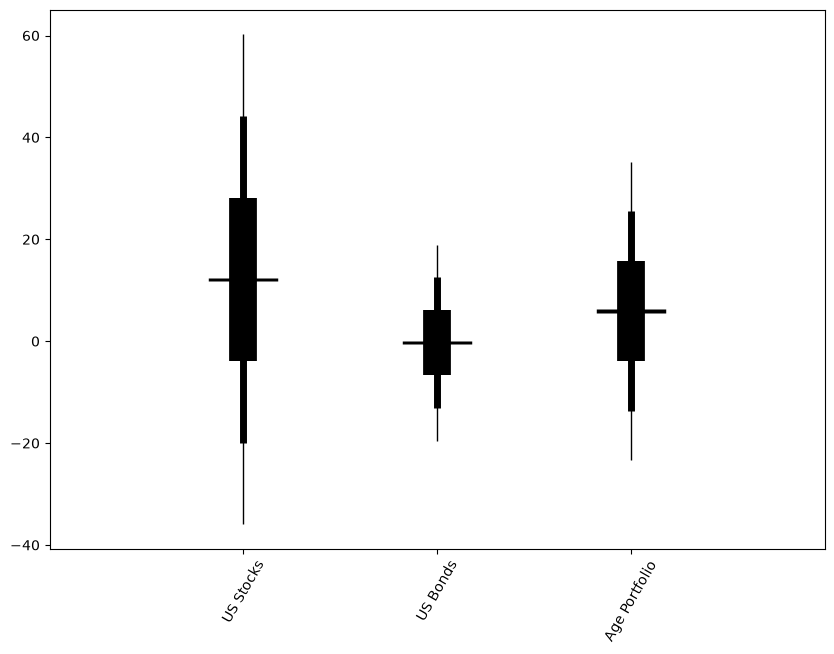

In [13]:
# Display Results
summary = bb.summary(df, portfolio_option, annual_ret, std_dev, sharpe_ratio)
summary

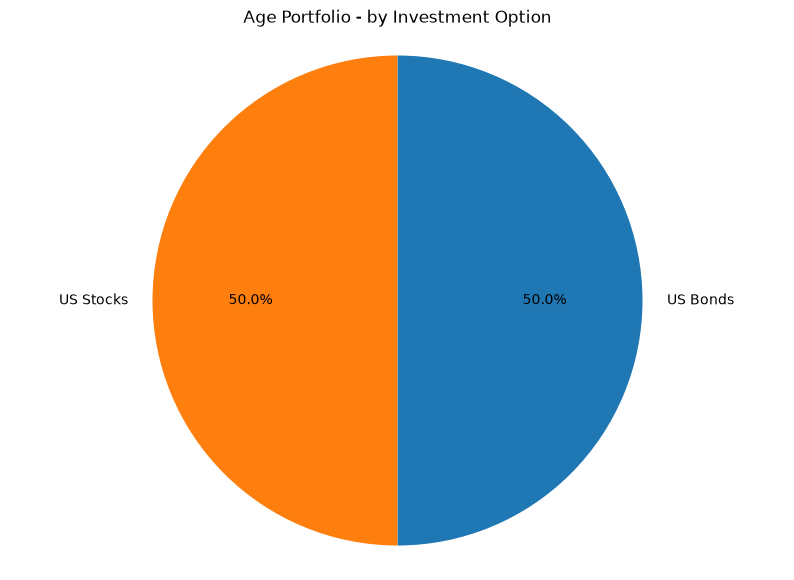

US Bonds    0.50
US Stocks   0.50



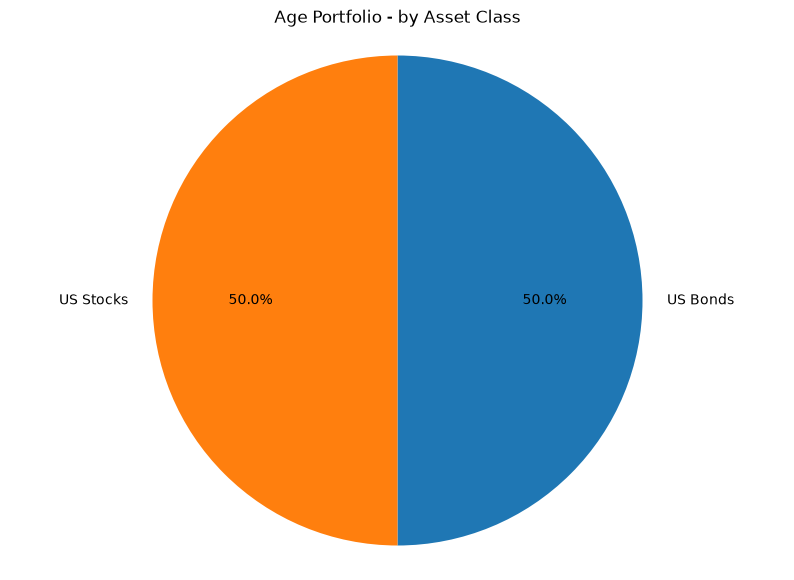

US Bonds    0.50
US Stocks   0.50



In [14]:
# Show pie charts of investment and asset class weights
bb.show_pie_charts(df, portfolio_option, charts=['Investment Option', 'Asset Class'])

In [15]:
# Show exact weights
bb.print_portfolio(portfolio_option)

Age Portfolio Weights:
    US Stocks                      0.5000
    US Bonds                       0.5000


### Optimize Portfolio

In [16]:
# Run_portfolio_optimizer = True will run portfolio optimizer after portfolio analysis is complete
run_portfolio_optimizer = False

In [17]:
# Optimize sharpe ratio while specifying Annual Rate, Worst Typical Down Year,
# and Black Swan.  Setting a constraint to None optimizes absolute Sharpe Ratio
# without regard to that constraint.

'''
constraints = {
    'Annual Return': 12,
    'Worst Typical Down Year': -5,
    'Black Swan': None
}
'''

constraints = {
    'Annual Return': 6,
    'Worst Typical Down Year': None,
    'Black Swan': -20
}

if run_portfolio_optimizer:
    bb.optimizer(df, portfolio_option, constraints)

### Use Sharpe Ratio adjusted weights
Recommend that you also try using Sharpe Ratio adjusted weights and compare those results with the Optimized Portflio.  
It tends to produce a higher Annual Return while keeping the allocations more balanced than the Optimizer.  (See 'Analysis Options' section).